In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid
import mpl_scatter_density
from matplotlib.colors import LinearSegmentedColormap

**load data**

In [2]:
#read in 733 sample x 3.5+ million DHS presence/absence matrix
dhs = pd.read_table('/home/ctrader/Hold/DHS/dat_bin_FDR01_hg38.txt.gz', header=None).T
print(dhs.shape)
dhs_array = dhs.to_numpy()
del dhs

(733, 3591898)


In [13]:
del dhs_array

In [3]:
#results from fill in 0.01%
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_1_cycle_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_1_cycle=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_updated_dhs_array_all_delta_0001_2_cycles_CT20211221.pickle', 'rb')
updated_dhs_array_all_delta_0001_2_cycles=pickle.load(pickle_in)

In [14]:
del updated_dhs_array_all_delta_0001_2_cycles
del updated_dhs_array_all_delta_0001_1_cycle

In [2]:
file = '/home/ctrader/NMF_data/DHS_signal_matrix/DHS_peak_signal_hg38.75_20.normalized.GRCh38_no_alts_array_CT20220215.npy'
DHS_peak_signal_array = np.load(file)

In [5]:
n_biosamples, n_DHSs = DHS_peak_signal_array.shape

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [4]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_added_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_first_01_removed_calls_delta_biosample_DHS_1_cycle_CT20220209.pickle', 'rb')
first_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

first_01_added_calls_delta_vals = first_01_added_calls_delta_biosample_DHS[0, :]
first_01_added_calls_biosample_inds = first_01_added_calls_delta_biosample_DHS[1, :].astype(int)
first_01_added_calls_DHS_inds = first_01_added_calls_delta_biosample_DHS[2, :].astype(int)

first_01_removed_calls_delta_vals = first_01_removed_calls_delta_biosample_DHS[0, :]
first_01_removed_calls_biosample_inds = first_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
first_01_removed_calls_DHS_inds = first_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [5]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_added_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'rb')
second_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_second_01_removed_calls_delta_biosample_DHS_2_cycles_CT20220209.pickle', 'rb')
second_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

second_01_added_calls_delta_vals = second_01_added_calls_delta_biosample_DHS[0, :]
second_01_added_calls_biosample_inds = second_01_added_calls_delta_biosample_DHS[1, :].astype(int)
second_01_added_calls_DHS_inds = second_01_added_calls_delta_biosample_DHS[2, :].astype(int)

second_01_removed_calls_delta_vals = second_01_removed_calls_delta_biosample_DHS[0, :]
second_01_removed_calls_biosample_inds = second_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
second_01_removed_calls_DHS_inds = second_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [6]:
#load just the 0.01% call changes
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_added_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'rb')
third_01_added_calls_delta_biosample_DHS=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_third_01_removed_calls_delta_biosample_DHS_3_cycles_CT20220209.pickle', 'rb')
third_01_removed_calls_delta_biosample_DHS=pickle.load(pickle_in)

third_01_added_calls_delta_vals = third_01_added_calls_delta_biosample_DHS[0, :]
third_01_added_calls_biosample_inds = third_01_added_calls_delta_biosample_DHS[1, :].astype(int)
third_01_added_calls_DHS_inds = third_01_added_calls_delta_biosample_DHS[2, :].astype(int)

third_01_removed_calls_delta_vals = third_01_removed_calls_delta_biosample_DHS[0, :]
third_01_removed_calls_biosample_inds = third_01_removed_calls_delta_biosample_DHS[1, :].astype(int)
third_01_removed_calls_DHS_inds = third_01_removed_calls_delta_biosample_DHS[2, :].astype(int)

In [2]:
#fill in 0.01% order
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_1_cycle_CT20220201.pickle', 'rb')
diff_flat_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_2_cycles_CT20220201.pickle', 'rb')
diff_flat_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_diff_flat_all_delta_0001_3_cycles_CT20220201.pickle', 'rb')
diff_flat_all_delta_0001_3_cycles=pickle.load(pickle_in)

pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_1_cycle_CT20220201.pickle', 'rb')
sorted_diff_flat_all_delta_0001_1_cycle=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_2_cycles_CT20220201.pickle', 'rb')
sorted_diff_flat_all_delta_0001_2_cycles=pickle.load(pickle_in)
pickle_in = open('/home/ctrader/Hold/NMF/DHS/pickled_data/NMF_fill_in_sorted_diff_flat_all_delta_0001_3_cycles_CT20220201.pickle', 'rb')
sorted_diff_flat_all_delta_0001_3_cycles=pickle.load(pickle_in)

In [3]:
n_DHSs = len(diff_flat_all_delta_0001_1_cycle)/733

In [4]:
first_all_calls_delta_vals = diff_flat_all_delta_0001_1_cycle[sorted_diff_flat_all_delta_0001_1_cycle]
first_all_calls_biosample_inds = sorted_diff_flat_all_delta_0001_1_cycle//n_DHSs
first_all_calls_DHS_inds = sorted_diff_flat_all_delta_0001_1_cycle % n_DHSs
del sorted_diff_flat_all_delta_0001_1_cycle
del diff_flat_all_delta_0001_1_cycle

second_all_calls_delta_vals = diff_flat_all_delta_0001_2_cycles[sorted_diff_flat_all_delta_0001_2_cycles]
second_all_calls_biosample_inds = sorted_diff_flat_all_delta_0001_2_cycles//n_DHSs
second_all_calls_DHS_inds = sorted_diff_flat_all_delta_0001_2_cycles % n_DHSs
del sorted_diff_flat_all_delta_0001_2_cycles
del diff_flat_all_delta_0001_2_cycles

third_all_calls_delta_vals = diff_flat_all_delta_0001_3_cycles[sorted_diff_flat_all_delta_0001_3_cycles]
third_all_calls_biosample_inds = sorted_diff_flat_all_delta_0001_3_cycles//n_DHSs
third_all_calls_DHS_inds = sorted_diff_flat_all_delta_0001_3_cycles % n_DHSs
del sorted_diff_flat_all_delta_0001_3_cycles
del diff_flat_all_delta_0001_3_cycles

In [5]:
del first_all_calls_biosample_inds
del first_all_calls_DHS_inds
del second_all_calls_biosample_inds
del second_all_calls_DHS_inds
del third_all_calls_biosample_inds
del third_all_calls_DHS_inds

**Removing 1 to 1 interactions**

In [7]:
previous_call_value_first_01_added_calls = []
for biosample, dhs in zip(first_01_added_calls_biosample_inds, first_01_added_calls_DHS_inds):
    previous_call_value_first_01_added_calls.append(dhs_array[biosample, dhs])
previous_call_value_first_01_added_calls = np.array(previous_call_value_first_01_added_calls)

first_01_added_calls_previously_0 = np.where(previous_call_value_first_01_added_calls==0)[0]

In [8]:
first_01_added_calls_delta_vals_filtered = first_01_added_calls_delta_vals[first_01_added_calls_previously_0]
first_01_added_calls_biosample_inds_filtered = first_01_added_calls_biosample_inds[first_01_added_calls_previously_0]
first_01_added_calls_DHS_inds_filtered = first_01_added_calls_DHS_inds[first_01_added_calls_previously_0] 

In [9]:
previous_call_value_second_01_added_calls = []
for biosample, dhs in zip(second_01_added_calls_biosample_inds, second_01_added_calls_DHS_inds):
    previous_call_value_second_01_added_calls.append(updated_dhs_array_all_delta_0001_1_cycle[biosample, dhs])
previous_call_value_second_01_added_calls = np.array(previous_call_value_second_01_added_calls)

second_01_added_calls_previously_0 = np.where(previous_call_value_second_01_added_calls==0)[0]

In [10]:
second_01_added_calls_delta_vals_filtered = second_01_added_calls_delta_vals[second_01_added_calls_previously_0]
second_01_added_calls_biosample_inds_filtered = second_01_added_calls_biosample_inds[second_01_added_calls_previously_0]
second_01_added_calls_DHS_inds_filtered = second_01_added_calls_DHS_inds[second_01_added_calls_previously_0]

In [11]:
previous_call_value_third_01_added_calls = []
for biosample, dhs in zip(third_01_added_calls_biosample_inds, third_01_added_calls_DHS_inds):
    previous_call_value_third_01_added_calls.append(updated_dhs_array_all_delta_0001_2_cycles[biosample, dhs])
previous_call_value_third_01_added_calls = np.array(previous_call_value_third_01_added_calls)

third_01_added_calls_previously_0 = np.where(previous_call_value_third_01_added_calls==0)[0]

In [12]:
third_01_added_calls_delta_vals_filtered = third_01_added_calls_delta_vals[third_01_added_calls_previously_0]
third_01_added_calls_biosample_inds_filtered = third_01_added_calls_biosample_inds[third_01_added_calls_previously_0]
third_01_added_calls_DHS_inds_filtered = third_01_added_calls_DHS_inds[third_01_added_calls_previously_0]

In [34]:
print('Percent of calls changed from 1 to 1 in cycle 1: %s' %((1-len(first_01_added_calls_previously_0)/len(first_01_added_calls_biosample_inds))*100))
print('Percent of calls changed from 1 to 1 in cycle 2: %s' %((1-len(second_01_added_calls_previously_0)/len(second_01_added_calls_biosample_inds))*100))
print('Percent of calls changed from 1 to 1 in cycle 3: %s' %((1-len(third_01_added_calls_previously_0)/len(third_01_added_calls_biosample_inds))*100))

Percent of calls changed from 1 to 1 in cycle 1: 2.811011599553337
Percent of calls changed from 1 to 1 in cycle 2: 4.255828262801664
Percent of calls changed from 1 to 1 in cycle 3: 5.251323655644436


Text(0.5, 1.0, 'Delta Values for Added (Previously 0) and Removed Calls from Each Cycle\nDelta Fill-in, Fill Size=0.01%')

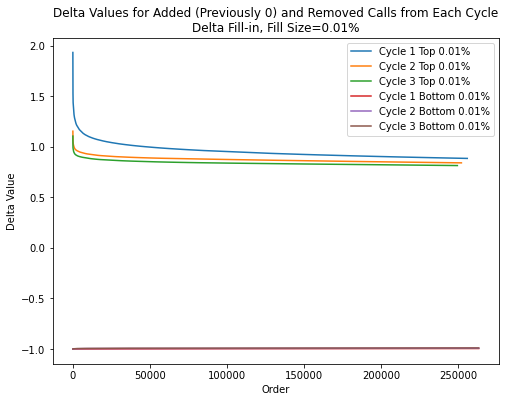

In [15]:
fig = plt.figure(figsize=(8,6))
fig.patch.set_facecolor('white')

plt.plot(np.arange(len(first_01_added_calls_delta_vals_filtered)), first_01_added_calls_delta_vals_filtered)
plt.plot(np.arange(len(second_01_added_calls_delta_vals_filtered)), second_01_added_calls_delta_vals_filtered)
plt.plot(np.arange(len(third_01_added_calls_delta_vals_filtered)), third_01_added_calls_delta_vals_filtered)

plt.plot(np.arange(len(first_01_removed_calls_delta_vals)), first_01_removed_calls_delta_vals)
plt.plot(np.arange(len(second_01_removed_calls_delta_vals)), second_01_removed_calls_delta_vals)
plt.plot(np.arange(len(third_01_removed_calls_delta_vals)), third_01_removed_calls_delta_vals)

plt.legend(['Cycle 1 Top 0.01%', 'Cycle 2 Top 0.01%', 'Cycle 3 Top 0.01%', 'Cycle 1 Bottom 0.01%', 'Cycle 2 Bottom 0.01%', 'Cycle 3 Bottom 0.01%',])

plt.xlabel('Order')
plt.ylabel('Delta Value')
plt.title('Delta Values for Added (Previously 0) and Removed Calls from Each Cycle\nDelta Fill-in, Fill Size=0.01%')

**Plotting delta vs peak signal and peak signal vs mean signal for removed calls**

In [35]:
#finding peak signal values of removed calls
first_01_removed_calls_peak_signal = []
for i, j in zip(first_01_removed_calls_biosample_inds, first_01_removed_calls_DHS_inds):
    first_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
first_01_removed_calls_peak_signal = np.array(first_01_removed_calls_peak_signal)

second_01_removed_calls_peak_signal = []
for i, j in zip(second_01_removed_calls_biosample_inds, second_01_removed_calls_DHS_inds):
    second_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
second_01_removed_calls_peak_signal = np.array(second_01_removed_calls_peak_signal)
    
third_01_removed_calls_peak_signal = []
for i, j in zip(third_01_removed_calls_biosample_inds, third_01_removed_calls_DHS_inds):
    third_01_removed_calls_peak_signal.append(DHS_peak_signal_array[i, j])
third_01_removed_calls_peak_signal = np.array(third_01_removed_calls_peak_signal)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%')

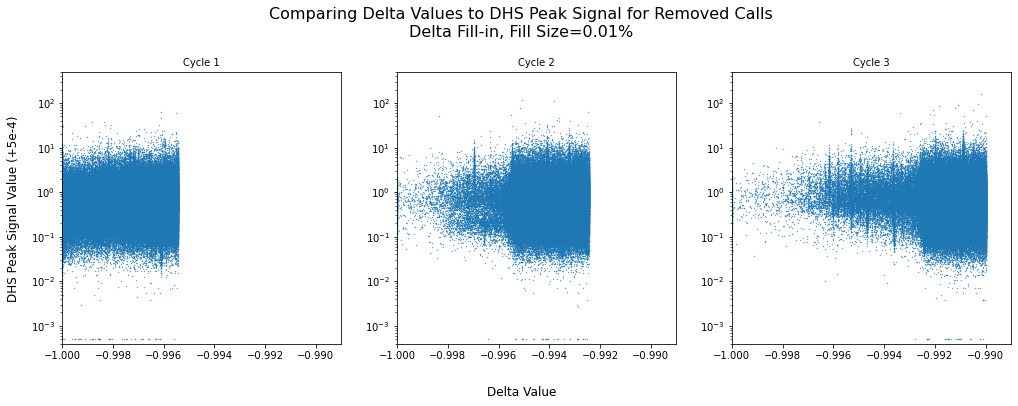

In [36]:
data = [first_01_removed_calls_delta_vals, 
        first_01_removed_calls_peak_signal+0.0005, 
        second_01_removed_calls_delta_vals, 
        second_01_removed_calls_peak_signal+0.0005, 
        third_01_removed_calls_delta_vals, 
        third_01_removed_calls_peak_signal+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.1)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([-1, -.989])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('log')

fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%')

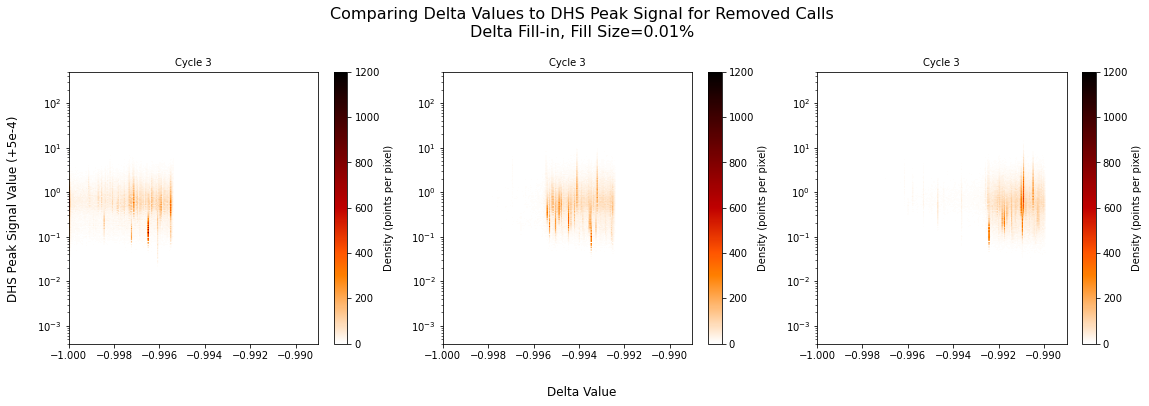

In [103]:
data = [first_01_removed_calls_delta_vals, 
        first_01_removed_calls_peak_signal+0.0005, 
        second_01_removed_calls_delta_vals, 
        second_01_removed_calls_peak_signal+0.0005, 
        third_01_removed_calls_delta_vals, 
        third_01_removed_calls_peak_signal+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig = plt.figure(figsize=(19,5))

fig.patch.set_facecolor('white')
ax1 = fig.add_subplot(1, 3, 1, projection='scatter_density')
ax2 = fig.add_subplot(1, 3, 2, projection='scatter_density')
ax3 = fig.add_subplot(1, 3, 3, projection='scatter_density')

scat = ax1.scatter_density(data[0], data[1], cmap='gist_heat_r', vmax=1200)
ax1.set_xlim([-1, -.989])
ax1.set_ylim([0.0004, 500])
ax1.set_yscale('log')
ax1.set_title(plot_titles[ind], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax1)


scat = ax2.scatter_density(data[2], data[3], cmap='gist_heat_r', vmax=1200)
ax2.set_xlim([-1, -.989])
ax2.set_ylim([0.0004, 500])
ax2.set_yscale('log')
ax2.set_title(plot_titles[ind], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax2)

scat = ax3.scatter_density(data[4], data[5], cmap='gist_heat_r', vmax=1200)
ax3.set_xlim([-1, -.989])
ax3.set_ylim([0.0004, 500])
ax3.set_yscale('log')
ax3.set_title(plot_titles[ind], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax3)

fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Removed Calls\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

In [37]:
#finding average signal value of DHS of removed calls
first_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[first_01_removed_calls_DHS_inds]['mean_signal'])
second_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[second_01_removed_calls_DHS_inds]['mean_signal'])
third_01_removed_calls_DHS_mean_signal = np.array(DHS_metadata.loc[third_01_removed_calls_DHS_inds]['mean_signal'])

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%')

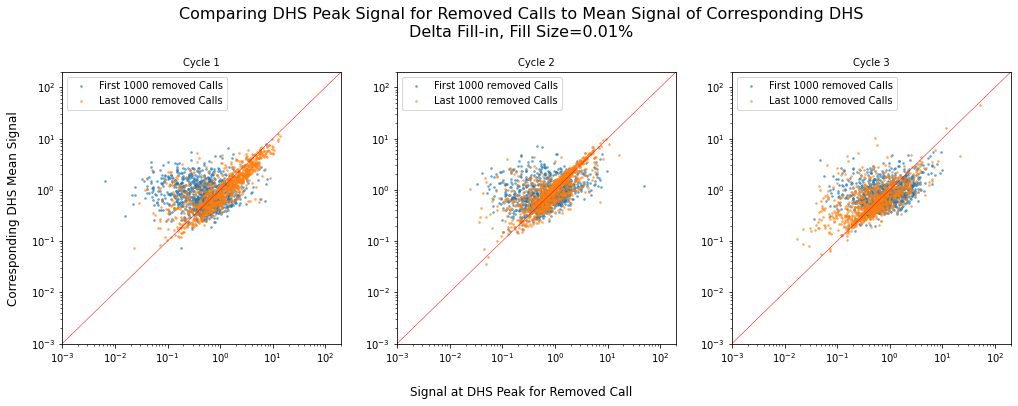

In [38]:
data = [first_01_removed_calls_peak_signal, 
        first_01_removed_calls_DHS_mean_signal, 
        second_01_removed_calls_peak_signal, 
        second_01_removed_calls_DHS_mean_signal, 
        third_01_removed_calls_peak_signal, 
        third_01_removed_calls_DHS_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][:1000], data[(2*ind)+1][:1000], s=3, alpha=0.5)
    scat = ax.scatter(data[2*ind][-1000:], data[(2*ind)+1][-1000:], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 removed Calls', 'Last 1000 removed Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Removed Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:77: RuntimeWarning: All-NaN slice encountered
  vmin = self._density_vmin(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:82: RuntimeWarning: All-NaN slice encountered
  vmax = self._density_vmax(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:77: RuntimeWarning: All-NaN slice encountered
  vmin = self._density_vmin(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:82: RuntimeWarning: All-NaN slice encountered
  vmax = self._density_vmax(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:77: RuntimeWarning: All-NaN slice encountered
  vmin = self._density_vmin(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-pa

Text(0.5, 0.97, 'Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS by Density\nDelta Fill-in, Fill Size=0.01%')

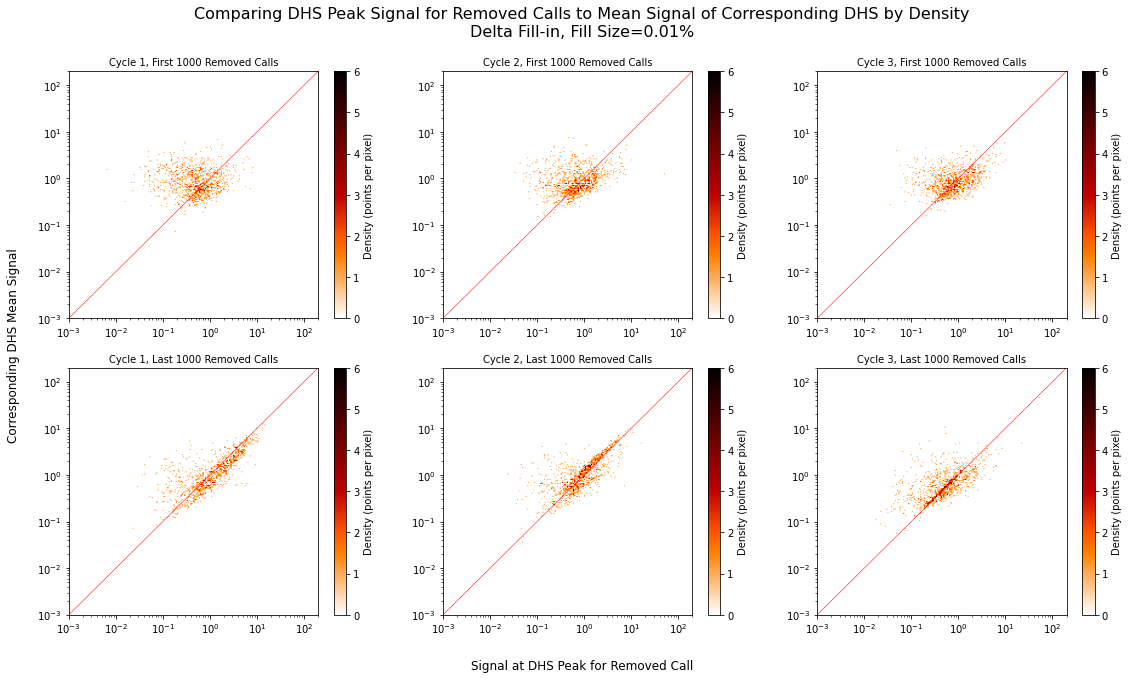

In [105]:
data = [first_01_removed_calls_peak_signal, 
        first_01_removed_calls_DHS_mean_signal, 
        second_01_removed_calls_peak_signal, 
        second_01_removed_calls_DHS_mean_signal, 
        third_01_removed_calls_peak_signal, 
        third_01_removed_calls_DHS_mean_signal]

fig = plt.figure(figsize=(19,10))

plot_titles = ['Cycle 1, First 1000 Removed Calls',
               'Cycle 2, First 1000 Removed Calls',
               'Cycle 3, First 1000 Removed Calls',
               'Cycle 1, Last 1000 Removed Calls',
               'Cycle 2, Last 1000 Removed Calls',
               'Cycle 3, Last 1000 Removed Calls',]

fig.patch.set_facecolor('white')
ax1 = fig.add_subplot(2, 3, 1, projection='scatter_density')
ax2 = fig.add_subplot(2, 3, 2, projection='scatter_density')
ax3 = fig.add_subplot(2, 3, 3, projection='scatter_density')
ax4 = fig.add_subplot(2, 3, 4, projection='scatter_density')
ax5 = fig.add_subplot(2, 3, 5, projection='scatter_density')
ax6 = fig.add_subplot(2, 3, 6, projection='scatter_density')

axes = [ax1, ax2, ax3, ax4, ax5, ax6]

for i in range(3):
    data_i = i
    scat = axes[i].scatter_density(data[2*data_i][:1000], data[(2*data_i)+1][:1000], cmap='gist_heat_r', vmax=6, vmin=0)
    axes[i].set_xlim([0.001, 200])
    axes[i].set_ylim([0.001, 200])
    axes[i].set_yscale('log')
    axes[i].set_xscale('log')
    fig.colorbar(scat, label='Density (points per pixel)', ax=axes[i])
    axes[i].plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    axes[i].set_title(plot_titles[i], fontsize=10)
    
    i += 3
    scat = axes[i].scatter_density(data[2*data_i][-1000:], data[(2*data_i)+1][-1000:], cmap='gist_heat_r', vmax=6, vmin=0)
    axes[i].set_xlim([0.001, 200])
    axes[i].set_ylim([0.001, 200])
    axes[i].set_yscale('log')
    axes[i].set_xscale('log')
    fig.colorbar(scat, label='Density (points per pixel)', ax=axes[i])
    axes[i].plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    axes[i].set_title(plot_titles[i], fontsize=10)
    
        
fig.text(0.5, 0.05, 'Signal at DHS Peak for Removed Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Removed Calls to Mean Signal of Corresponding DHS by Density\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=0.97)

**Plotting delta vs peak signal and peak signal vs mean signal for added calls**

In [39]:
#finding peak signal values of added calls
first_01_added_calls_peak_signal_filtered = []
for i, j in zip(first_01_added_calls_biosample_inds_filtered, first_01_added_calls_DHS_inds_filtered):
    first_01_added_calls_peak_signal_filtered.append(DHS_peak_signal_array[i, j])
first_01_added_calls_peak_signal_filtered = np.array(first_01_added_calls_peak_signal_filtered)

second_01_added_calls_peak_signal_filtered = []
for i, j in zip(second_01_added_calls_biosample_inds_filtered, second_01_added_calls_DHS_inds_filtered):
    second_01_added_calls_peak_signal_filtered.append(DHS_peak_signal_array[i, j])
second_01_added_calls_peak_signal_filtered = np.array(second_01_added_calls_peak_signal_filtered)
    
third_01_added_calls_peak_signal_filtered = []
for i, j in zip(third_01_added_calls_biosample_inds_filtered, third_01_added_calls_DHS_inds_filtered):
    third_01_added_calls_peak_signal_filtered.append(DHS_peak_signal_array[i, j])
third_01_added_calls_peak_signal_filtered = np.array(third_01_added_calls_peak_signal_filtered)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Added Calls (Previously 0)\nDelta Fill-in, Fill Size=0.01%')

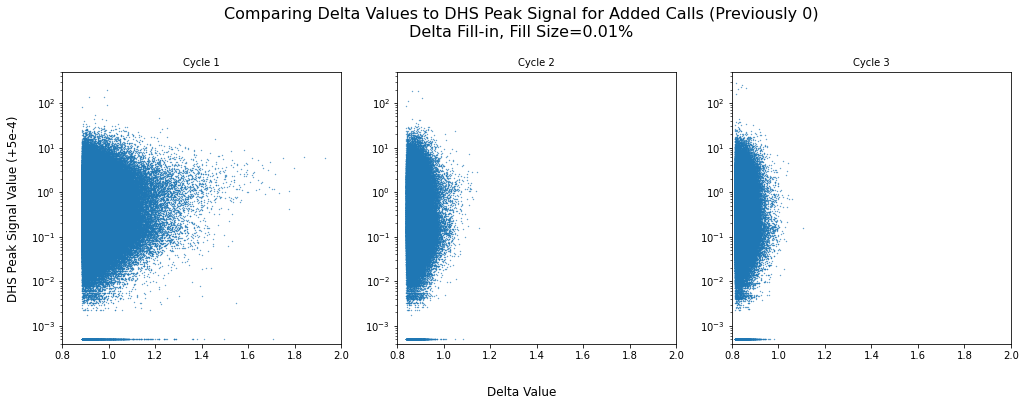

In [40]:
data = [first_01_added_calls_delta_vals_filtered, 
        first_01_added_calls_peak_signal_filtered+0.0005, 
        second_01_added_calls_delta_vals_filtered, 
        second_01_added_calls_peak_signal_filtered+0.0005, 
        third_01_added_calls_delta_vals_filtered, 
        third_01_added_calls_peak_signal_filtered+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind], data[(2*ind)+1], s=0.1)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.8, 2])
    ax.set_ylim([0.0004, 500])
    ax.set_yscale('log')
#     ax.set_yscale('symlog')

fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Added Calls (Previously 0)\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for Added Calls (Previously 0) by Density\nDelta Fill-in, Fill Size=0.01%')

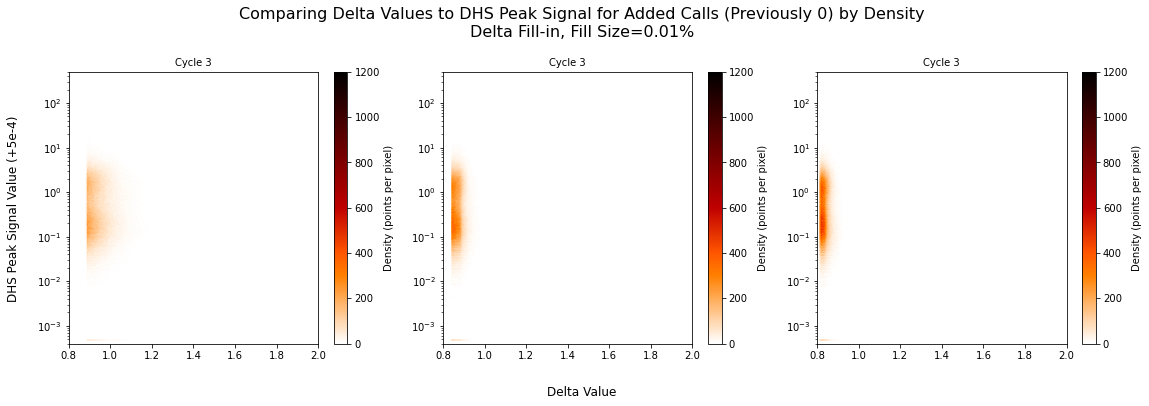

In [52]:
data = [first_01_added_calls_delta_vals_filtered, 
        first_01_added_calls_peak_signal_filtered+0.0005, 
        second_01_added_calls_delta_vals_filtered, 
        second_01_added_calls_peak_signal_filtered+0.0005, 
        third_01_added_calls_delta_vals_filtered, 
        third_01_added_calls_peak_signal_filtered+0.0005]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig = plt.figure(figsize=(19,5))

fig.patch.set_facecolor('white')
ax1 = fig.add_subplot(1, 3, 1, projection='scatter_density')
ax2 = fig.add_subplot(1, 3, 2, projection='scatter_density')
ax3 = fig.add_subplot(1, 3, 3, projection='scatter_density')

scat = ax1.scatter_density(data[0], data[1], cmap='gist_heat_r', vmax=1200)
ax1.set_xlim([0.8, 2])
ax1.set_ylim([0.0004, 500])
ax1.set_yscale('log')
ax1.set_title(plot_titles[ind], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax1)


scat = ax2.scatter_density(data[2], data[3], cmap='gist_heat_r', vmax=1200)
ax2.set_xlim([0.8, 2])
ax2.set_ylim([0.0004, 500])
ax2.set_yscale('log')
ax2.set_title(plot_titles[ind], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax2)

scat = ax3.scatter_density(data[4], data[5], cmap='gist_heat_r', vmax=1200)
ax3.set_xlim([0.8, 2])
ax3.set_ylim([0.0004, 500])
ax3.set_yscale('log')
ax3.set_title(plot_titles[ind], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax3)

fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for Added Calls (Previously 0) by Density\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

In [41]:
#finding average signal value of filtered added calls
first_01_added_calls_DHS_filtered_mean_signal = np.array(DHS_metadata.loc[first_01_added_calls_DHS_inds_filtered]['mean_signal'])
second_01_added_calls_DHS_filtered_mean_signal = np.array(DHS_metadata.loc[second_01_added_calls_DHS_inds_filtered]['mean_signal'])
third_01_added_calls_DHS_filtered_mean_signal = np.array(DHS_metadata.loc[third_01_added_calls_DHS_inds_filtered]['mean_signal'])

Text(0.5, 1.06, 'Comparing DHS Peak Signal for Added Calls (Previously 0) to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%')

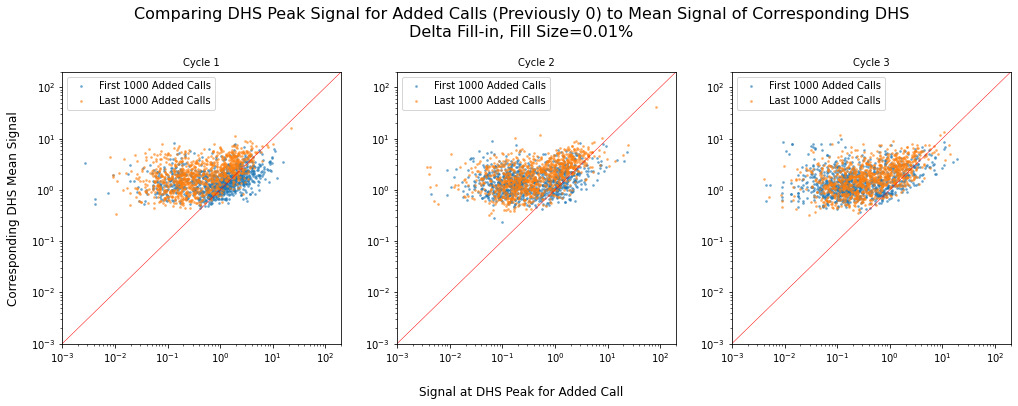

In [42]:
data = [first_01_added_calls_peak_signal_filtered,
        first_01_added_calls_DHS_filtered_mean_signal, 
        second_01_added_calls_peak_signal_filtered, 
        second_01_added_calls_DHS_filtered_mean_signal, 
        third_01_added_calls_peak_signal_filtered, 
        third_01_added_calls_DHS_filtered_mean_signal]

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(17,5))
fig.patch.set_facecolor('white')

axes = axes.ravel()
for ax, ind in zip(axes, range(3)):
    scat = ax.scatter(data[2*ind][:1000], data[(2*ind)+1][:1000], s=3, alpha=0.5)
    scat = ax.scatter(data[2*ind][-1000:], data[(2*ind)+1][-1000:], s=3, alpha=0.5)
    ax.set_title(plot_titles[ind], fontsize=10)
    ax.set_xlim([0.001, 200])
    ax.set_ylim([0.001, 200])
    ax.set_xscale('log')
    ax.set_yscale('log')
    ax.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
    ax.plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    
# plt.legend(['First 1000 Added Calls', 'Last 1000 Added Calls'])
fig.text(0.5, -0.02, 'Signal at DHS Peak for Added Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls (Previously 0) to Mean Signal of Corresponding DHS\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:77: RuntimeWarning: All-NaN slice encountered
  vmin = self._density_vmin(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:82: RuntimeWarning: All-NaN slice encountered
  vmax = self._density_vmax(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:77: RuntimeWarning: All-NaN slice encountered
  vmin = self._density_vmin(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:82: RuntimeWarning: All-NaN slice encountered
  vmax = self._density_vmax(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/generic_density_artist.py:77: RuntimeWarning: All-NaN slice encountered
  vmin = self._density_vmin(array)
/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-pa

Text(0.5, 0.97, 'Comparing DHS Peak Signal for Added Calls (Previously 0) to Mean Signal of Corresponding DHS by Density\nDelta Fill-in, Fill Size=0.01%')

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/mpl_scatter_density/fixed_data_density_helper.py:53: RuntimeWarning: divide by zero encountered in log10
  self._x_log = np.log10(self._x)


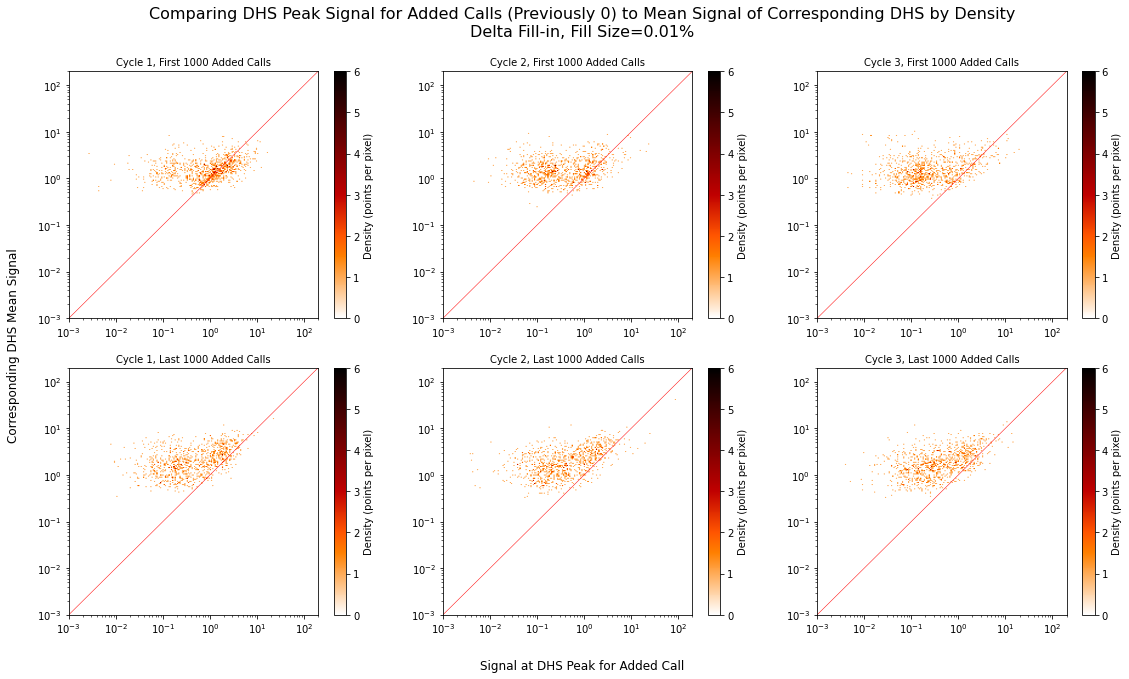

In [100]:
data = [first_01_added_calls_peak_signal_filtered,
        first_01_added_calls_DHS_filtered_mean_signal, 
        second_01_added_calls_peak_signal_filtered, 
        second_01_added_calls_DHS_filtered_mean_signal, 
        third_01_added_calls_peak_signal_filtered, 
        third_01_added_calls_DHS_filtered_mean_signal]

fig = plt.figure(figsize=(19,10))

plot_titles = ['Cycle 1, First 1000 Added Calls',
               'Cycle 2, First 1000 Added Calls',
               'Cycle 3, First 1000 Added Calls',
               'Cycle 1, Last 1000 Added Calls',
               'Cycle 2, Last 1000 Added Calls',
               'Cycle 3, Last 1000 Added Calls',]

fig.patch.set_facecolor('white')
ax1 = fig.add_subplot(2, 3, 1, projection='scatter_density')
ax2 = fig.add_subplot(2, 3, 2, projection='scatter_density')
ax3 = fig.add_subplot(2, 3, 3, projection='scatter_density')
ax4 = fig.add_subplot(2, 3, 4, projection='scatter_density')
ax5 = fig.add_subplot(2, 3, 5, projection='scatter_density')
ax6 = fig.add_subplot(2, 3, 6, projection='scatter_density')

axes = [ax1, ax2, ax3, ax4, ax5, ax6]

for i in range(3):
    data_i = i
    scat = axes[i].scatter_density(data[2*data_i][:1000], data[(2*data_i)+1][:1000], cmap='gist_heat_r', vmax=6, vmin=0)
    axes[i].set_xlim([0.001, 200])
    axes[i].set_ylim([0.001, 200])
    axes[i].set_yscale('log')
    axes[i].set_xscale('log')
    fig.colorbar(scat, label='Density (points per pixel)', ax=axes[i])
    axes[i].plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    axes[i].set_title(plot_titles[i], fontsize=10)
    
    i += 3
    scat = axes[i].scatter_density(data[2*data_i][-1000:], data[(2*data_i)+1][-1000:], cmap='gist_heat_r', vmax=6, vmin=0)
    axes[i].set_xlim([0.001, 200])
    axes[i].set_ylim([0.001, 200])
    axes[i].set_yscale('log')
    axes[i].set_xscale('log')
    fig.colorbar(scat, label='Density (points per pixel)', ax=axes[i])
    axes[i].plot(np.arange(300)-1, np.arange(300)-1, c='r', linewidth=0.5)
    axes[i].set_title(plot_titles[i], fontsize=10)
    
        
fig.text(0.5, 0.05, 'Signal at DHS Peak for Added Call', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'Corresponding DHS Mean Signal', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing DHS Peak Signal for Added Calls (Previously 0) to Mean Signal of Corresponding DHS by Density\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=0.97)

**delta vs peak signal for all calls**

In [8]:
#finding peak signal values of removed calls
first_all_calls_peak_signal = []
for i, j in zip(first_all_calls_biosample_inds, first_all_calls_DHS_inds):
    first_all_calls_peak_signal.append(DHS_peak_signal_array[int(i), int(j)])
first_all_calls_peak_signal = np.array(first_all_calls_peak_signal)
del first_all_calls_biosample_inds
del first_all_calls_DHS_inds

second_all_calls_peak_signal = []
for i, j in zip(second_all_calls_biosample_inds, second_all_calls_DHS_inds):
    second_all_calls_peak_signal.append(DHS_peak_signal_array[int(i), int(j)])
second_all_calls_peak_signal = np.array(second_all_calls_peak_signal)
del second_all_calls_biosample_inds
del second_all_calls_DHS_inds
    
third_all_calls_peak_signal = []
for i, j in zip(third_all_calls_biosample_inds, third_all_calls_DHS_inds):
    third_all_calls_peak_signal.append(DHS_peak_signal_array[int(i), int(j)])
third_all_calls_peak_signal = np.array(third_all_calls_peak_signal)
del third_all_calls_biosample_inds
del third_all_calls_DHS_inds

In [10]:
#rename!!! with CT20220217
outfile = '/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/cycle_1_first_all_calls_peak_signal.npy'
np.save(outfile, first_all_calls_peak_signal)
outfile = '/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/cycle_2_second_all_calls_peak_signal.npy'
np.save(outfile, second_all_calls_peak_signal)
outfile = '/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/cycle_3_third_all_calls_peak_signal.npy'
np.save(outfile, third_all_calls_peak_signal)

In [6]:
outfile = '/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/cycle_1_first_all_calls_peak_signal.npy'
first_all_calls_peak_signal = np.load(outfile)

outfile = '/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/cycle_2_second_all_calls_peak_signal.npy'
second_all_calls_peak_signal = np.load(outfile)

outfile = '/home/ctrader/AG/AugmentedGenomics/recommendersystems/NMF/DHS/cycle_3_third_all_calls_peak_signal.npy'
third_all_calls_peak_signal = np.load(outfile)

In [14]:
del first_all_calls_delta_vals
del first_all_calls_peak_signal
del second_all_calls_delta_vals
del second_all_calls_peak_signal
del third_all_calls_delta_vals
del third_all_calls_peak_signal

Text(0.5, 1.06, 'Comparing Delta Values to DHS Peak Signal for All Calls by Density\nDelta Fill-in, Fill Size=0.01%')

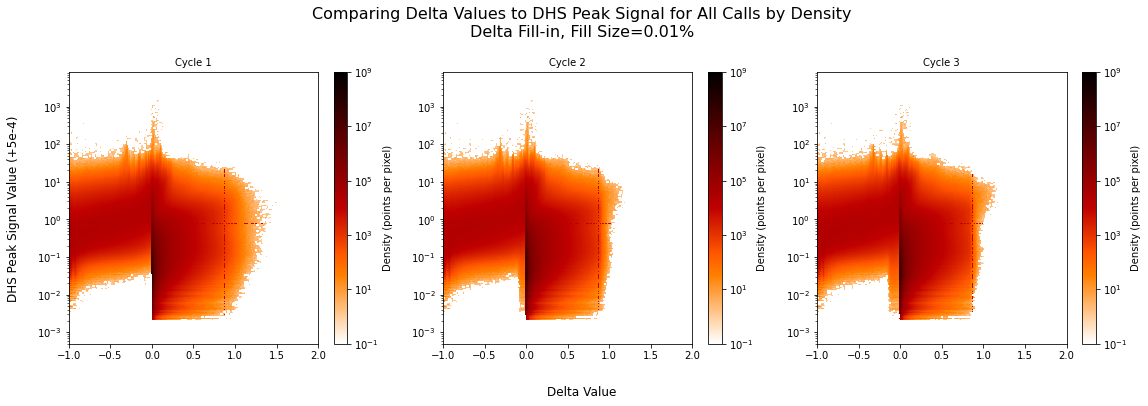

In [19]:
import matplotlib.colors as colors

plot_titles = ['Cycle 1', 'Cycle 2', 'Cycle 3']

fig = plt.figure(figsize=(19,5))

fig.patch.set_facecolor('white')
ax1 = fig.add_subplot(1, 3, 1, projection='scatter_density')
ax2 = fig.add_subplot(1, 3, 2, projection='scatter_density')
ax3 = fig.add_subplot(1, 3, 3, projection='scatter_density')

scat = ax1.scatter_density(data[0], data[1], cmap='gist_heat_r', norm=colors.LogNorm(vmin=0.1, vmax=1e9))
ax1.set_xlim([-1, 2])
# ax1.set_ylim([0.0004, 500])
ax1.set_yscale('log')
ax1.set_title(plot_titles[0], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax1)

scat = ax2.scatter_density(data[2], data[3], cmap='gist_heat_r', norm=colors.LogNorm(vmin=0.1, vmax=1e9))
ax2.set_xlim([-1, 2])
# ax2.set_ylim([0.0004, 500])
ax2.set_yscale('log')
ax2.set_title(plot_titles[1], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax2)

scat = ax3.scatter_density(data[4], data[5], cmap='gist_heat_r', norm=colors.LogNorm(vmin=0.1, vmax=1e9))
ax3.set_xlim([-1, 2])
# ax3.set_ylim([0.0004, 500])
ax3.set_yscale('log')
ax3.set_title(plot_titles[2], fontsize=10)
fig.colorbar(scat, label='Density (points per pixel)', ax=ax3)

fig.text(0.5, -0.02, 'Delta Value', ha='center', fontsize=12)
fig.text(0.08, 0.5, 'DHS Peak Signal Value (+5e-4)', va='center', rotation='vertical', fontsize=12)
plt.suptitle('Comparing Delta Values to DHS Peak Signal for All Calls by Density\nDelta Fill-in, Fill Size=0.01%', fontsize=16, x=0.5, y=1.06)